# Phase 3A — Figure 2: Activity-condition Relative Band Power (PRE vs POST)

**Purpose:** Plot participant-level ROI relative band power summarized by group for each activity condition, PRE vs POST.

- Math Activity1 and Math Activity2 are shown as separate figures.
- Reading Activity is shown as a separate figure.
- Each figure has 5 frequency-band rows × 5 ROI columns.
- Lines show group means; error bars show 95% t-based confidence intervals.
- No new inferential tests are performed.
- Relative power is compositional: a change in one band affects the proportions of the others.

This notebook discovers `eeg_roi_power_long.csv` from common project locations and saves outputs beside the source file.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import t

# Locate the source CSV robustly on Mac or hosted environments
candidates = [Path.cwd() / 'eeg_roi_power_long.csv', Path.home() / 'Term Project' / 'analysis' / 'eeg_roi_power_long.csv', Path.home() / 'Term Project' / 'eeg_roi_power_long.csv', Path.home() / 'eeg_roi_power_long.csv', Path('/mnt/data/eeg_roi_power_long.csv')]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    # Search likely project roots only
    for root in [Path.cwd(), Path.home() / 'Term Project', Path('/mnt/data')]:
        if root.exists():
            found = list(root.glob('**/eeg_roi_power_long.csv'))
            if found:
                csv_path = found[0]; break
if csv_path is None:
    raise FileNotFoundError('Could not locate eeg_roi_power_long.csv. Place it in the notebook folder or Term Project/analysis.')

output_dir = csv_path.parent / 'phase3_figures' / 'figure2_activity_relative_power'
output_dir.mkdir(parents=True, exist_ok=True)
print('Input:', csv_path)
print('Output:', output_dir)

Input: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv
Output: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure2_activity_relative_power


In [2]:
df = pd.read_csv(csv_path)
required = {'subject_id','session','condition','band','roi','relative_power_roi','task','group'}
missing_cols = required - set(df.columns)
if missing_cols: raise ValueError(f'Missing required columns: {missing_cols}')

BANDS = ['delta','theta','alpha','beta','gamma']
ROIS = ['Frontal','Central','Temporal','Parietal','Occipital']
SESSIONS = ['PRE','POST']
GROUPS = ['Control','Experiment']

# Select activity-only records and validate uniqueness / completeness
activity = df[df['condition'].isin(['Activity1','Activity2','Activity'])].copy()
key = ['subject_id','session','task','condition','band','roi']
duplicates = activity.duplicated(key).sum()
missing_power = activity['relative_power_roi'].isna().sum()
print('Activity records:', len(activity))
print('Duplicate keys:', duplicates)
print('Missing relative power:', missing_power)
if duplicates or missing_power: raise ValueError('Activity dataset QC failed.')
print('Conditions by task:', activity.groupby('task')['condition'].unique().to_dict())

Activity records: 4850
Duplicate keys: 0
Missing relative power: 0
Conditions by task: {'Math': <ArrowStringArray>
['Activity1', 'Activity2']
Length: 2, dtype: str, 'Reading': <ArrowStringArray>
['Activity']
Length: 1, dtype: str}


In [3]:
def summarize_cell(sub):
    vals = sub['relative_power_roi'].dropna().astype(float)
    n = len(vals); mean = vals.mean(); sd = vals.std(ddof=1) if n > 1 else np.nan
    if n > 1:
        ci = t.ppf(0.975, n-1) * sd / np.sqrt(n)
    else: ci = np.nan
    return pd.Series({'n':n,'mean':mean,'sd':sd,'ci95':ci})

summary = activity.groupby(['task','condition','band','roi','group','session'], observed=True).apply(summarize_cell, include_groups=False).reset_index()
summary.to_csv(output_dir / 'figure2_activity_relative_power_summary.csv', index=False)
print('Summary rows:', len(summary))
summary.head()

Summary rows: 300


,task,condition,band,roi,group,session,n,mean,sd,ci95
0,Math,Activity1,alpha,Central,Control,POST,15.0,4.343004,2.486900,1.377199
1,Math,Activity1,alpha,Central,Control,PRE,15.0,5.295154,2.141169,1.185740
2,Math,Activity1,alpha,Central,Experiment,POST,19.0,5.028795,3.444318,1.660108
3,Math,Activity1,alpha,Central,Experiment,PRE,19.0,5.511197,3.385736,1.631872
4,Math,Activity1,alpha,Frontal,Control,POST,15.0,3.706420,2.344001,1.298064


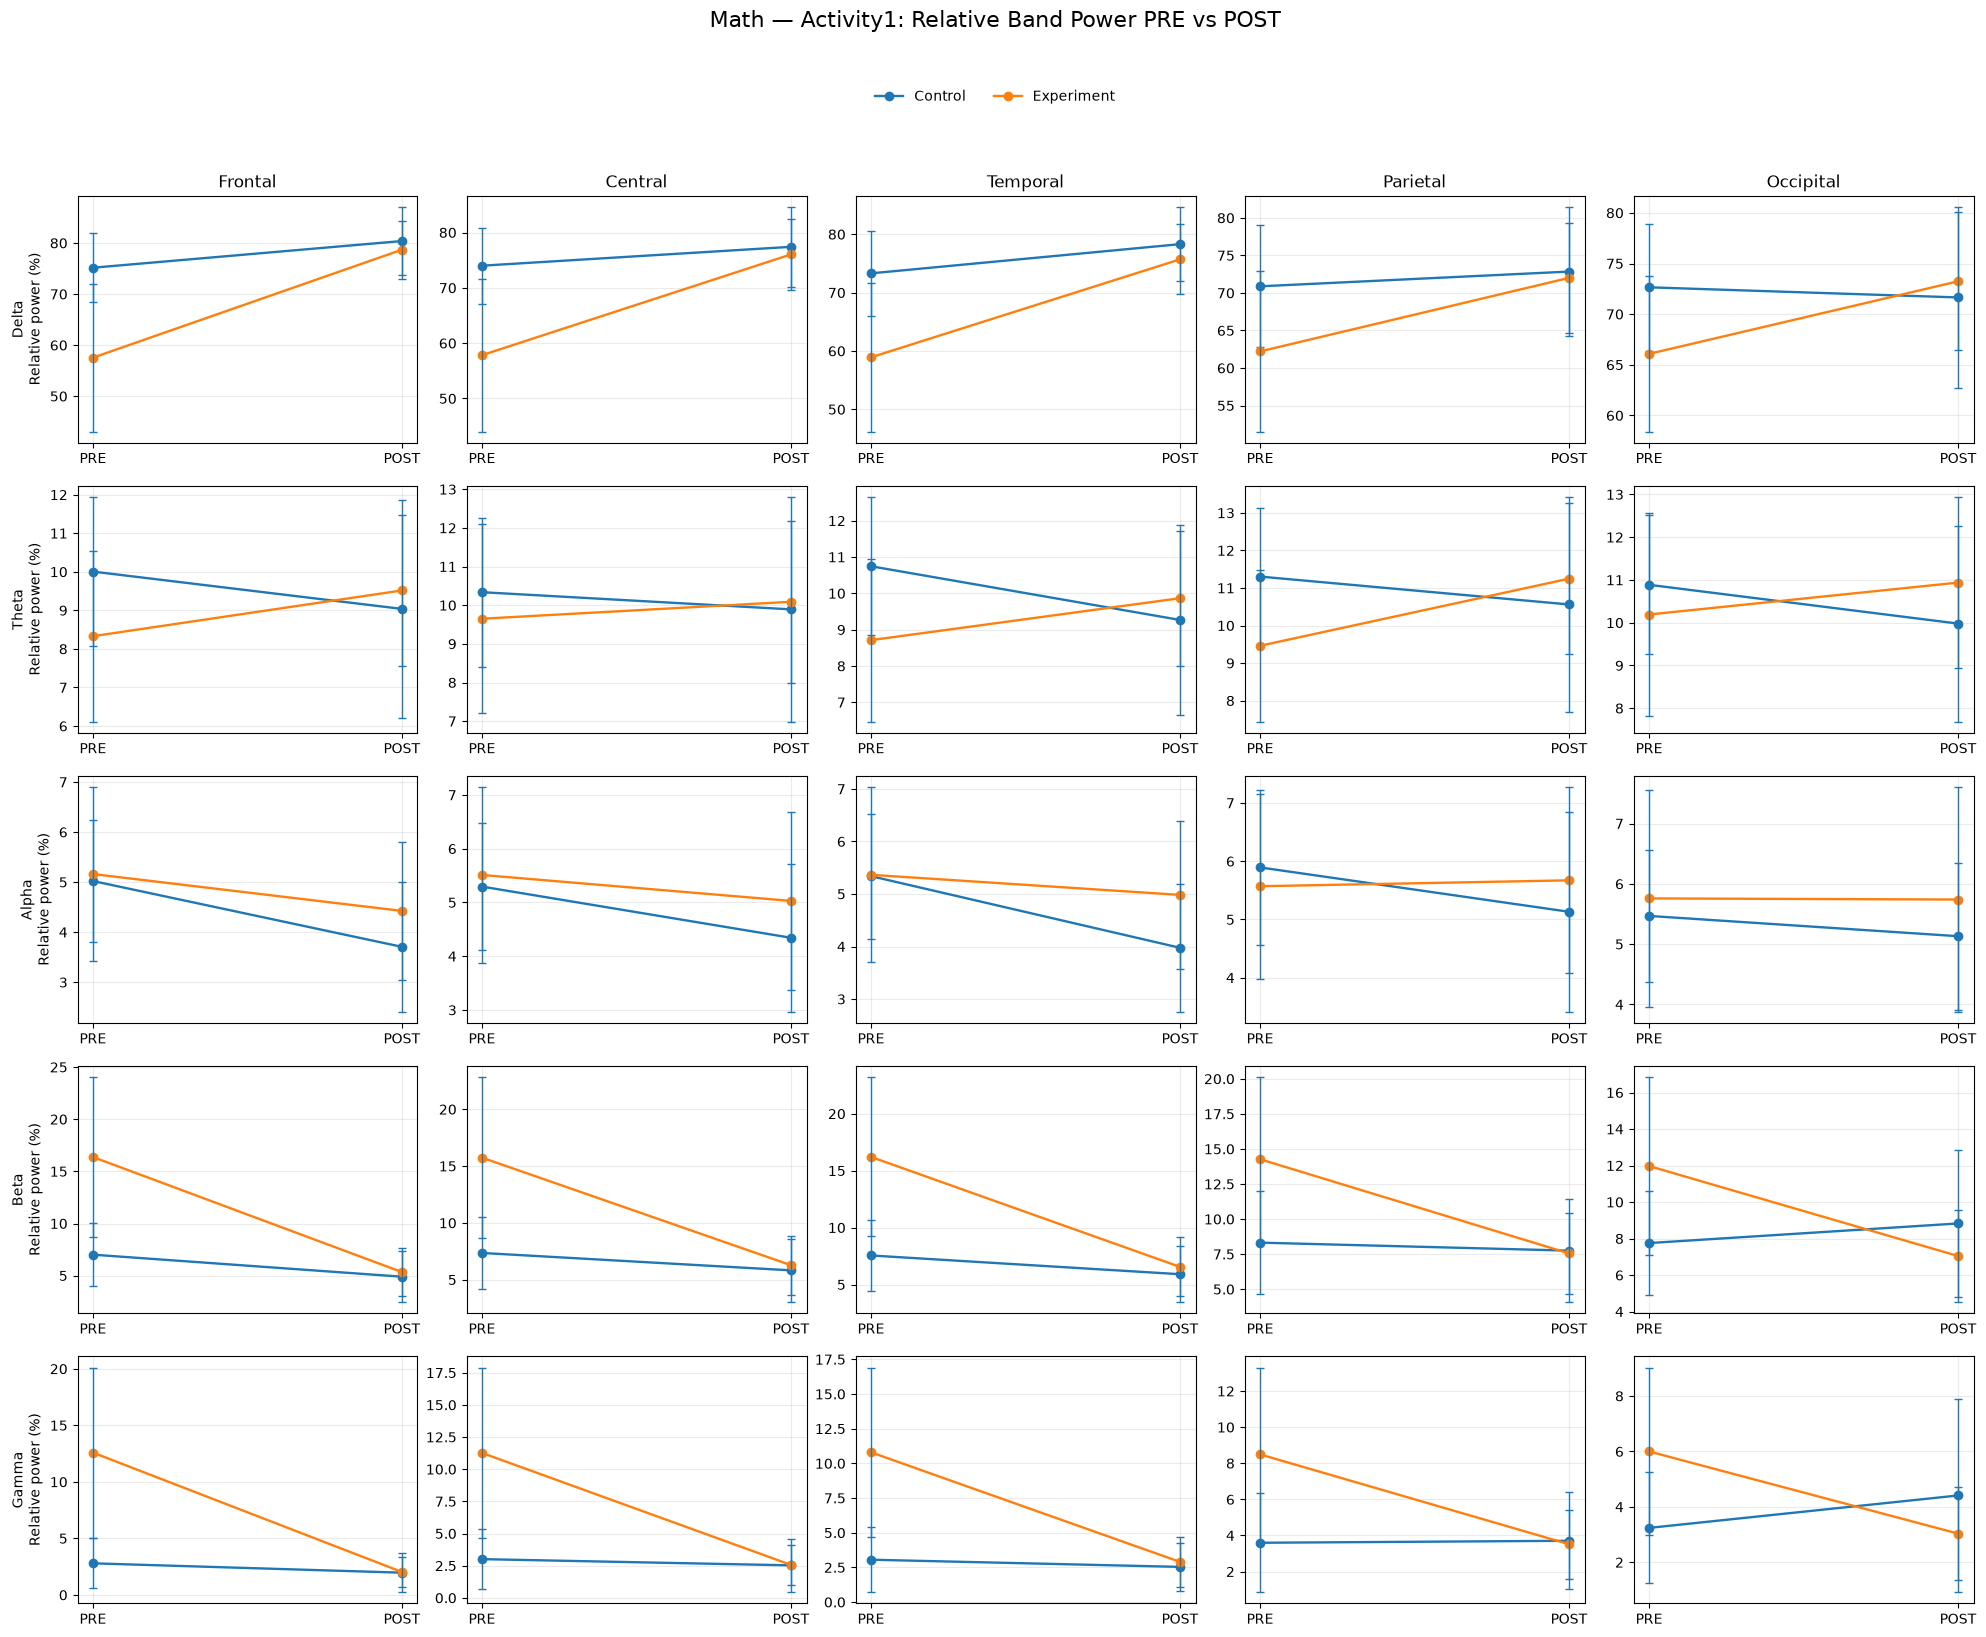

Saved: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure2_activity_relative_power/figure2_math_activity1_relative_power_pre_post.png


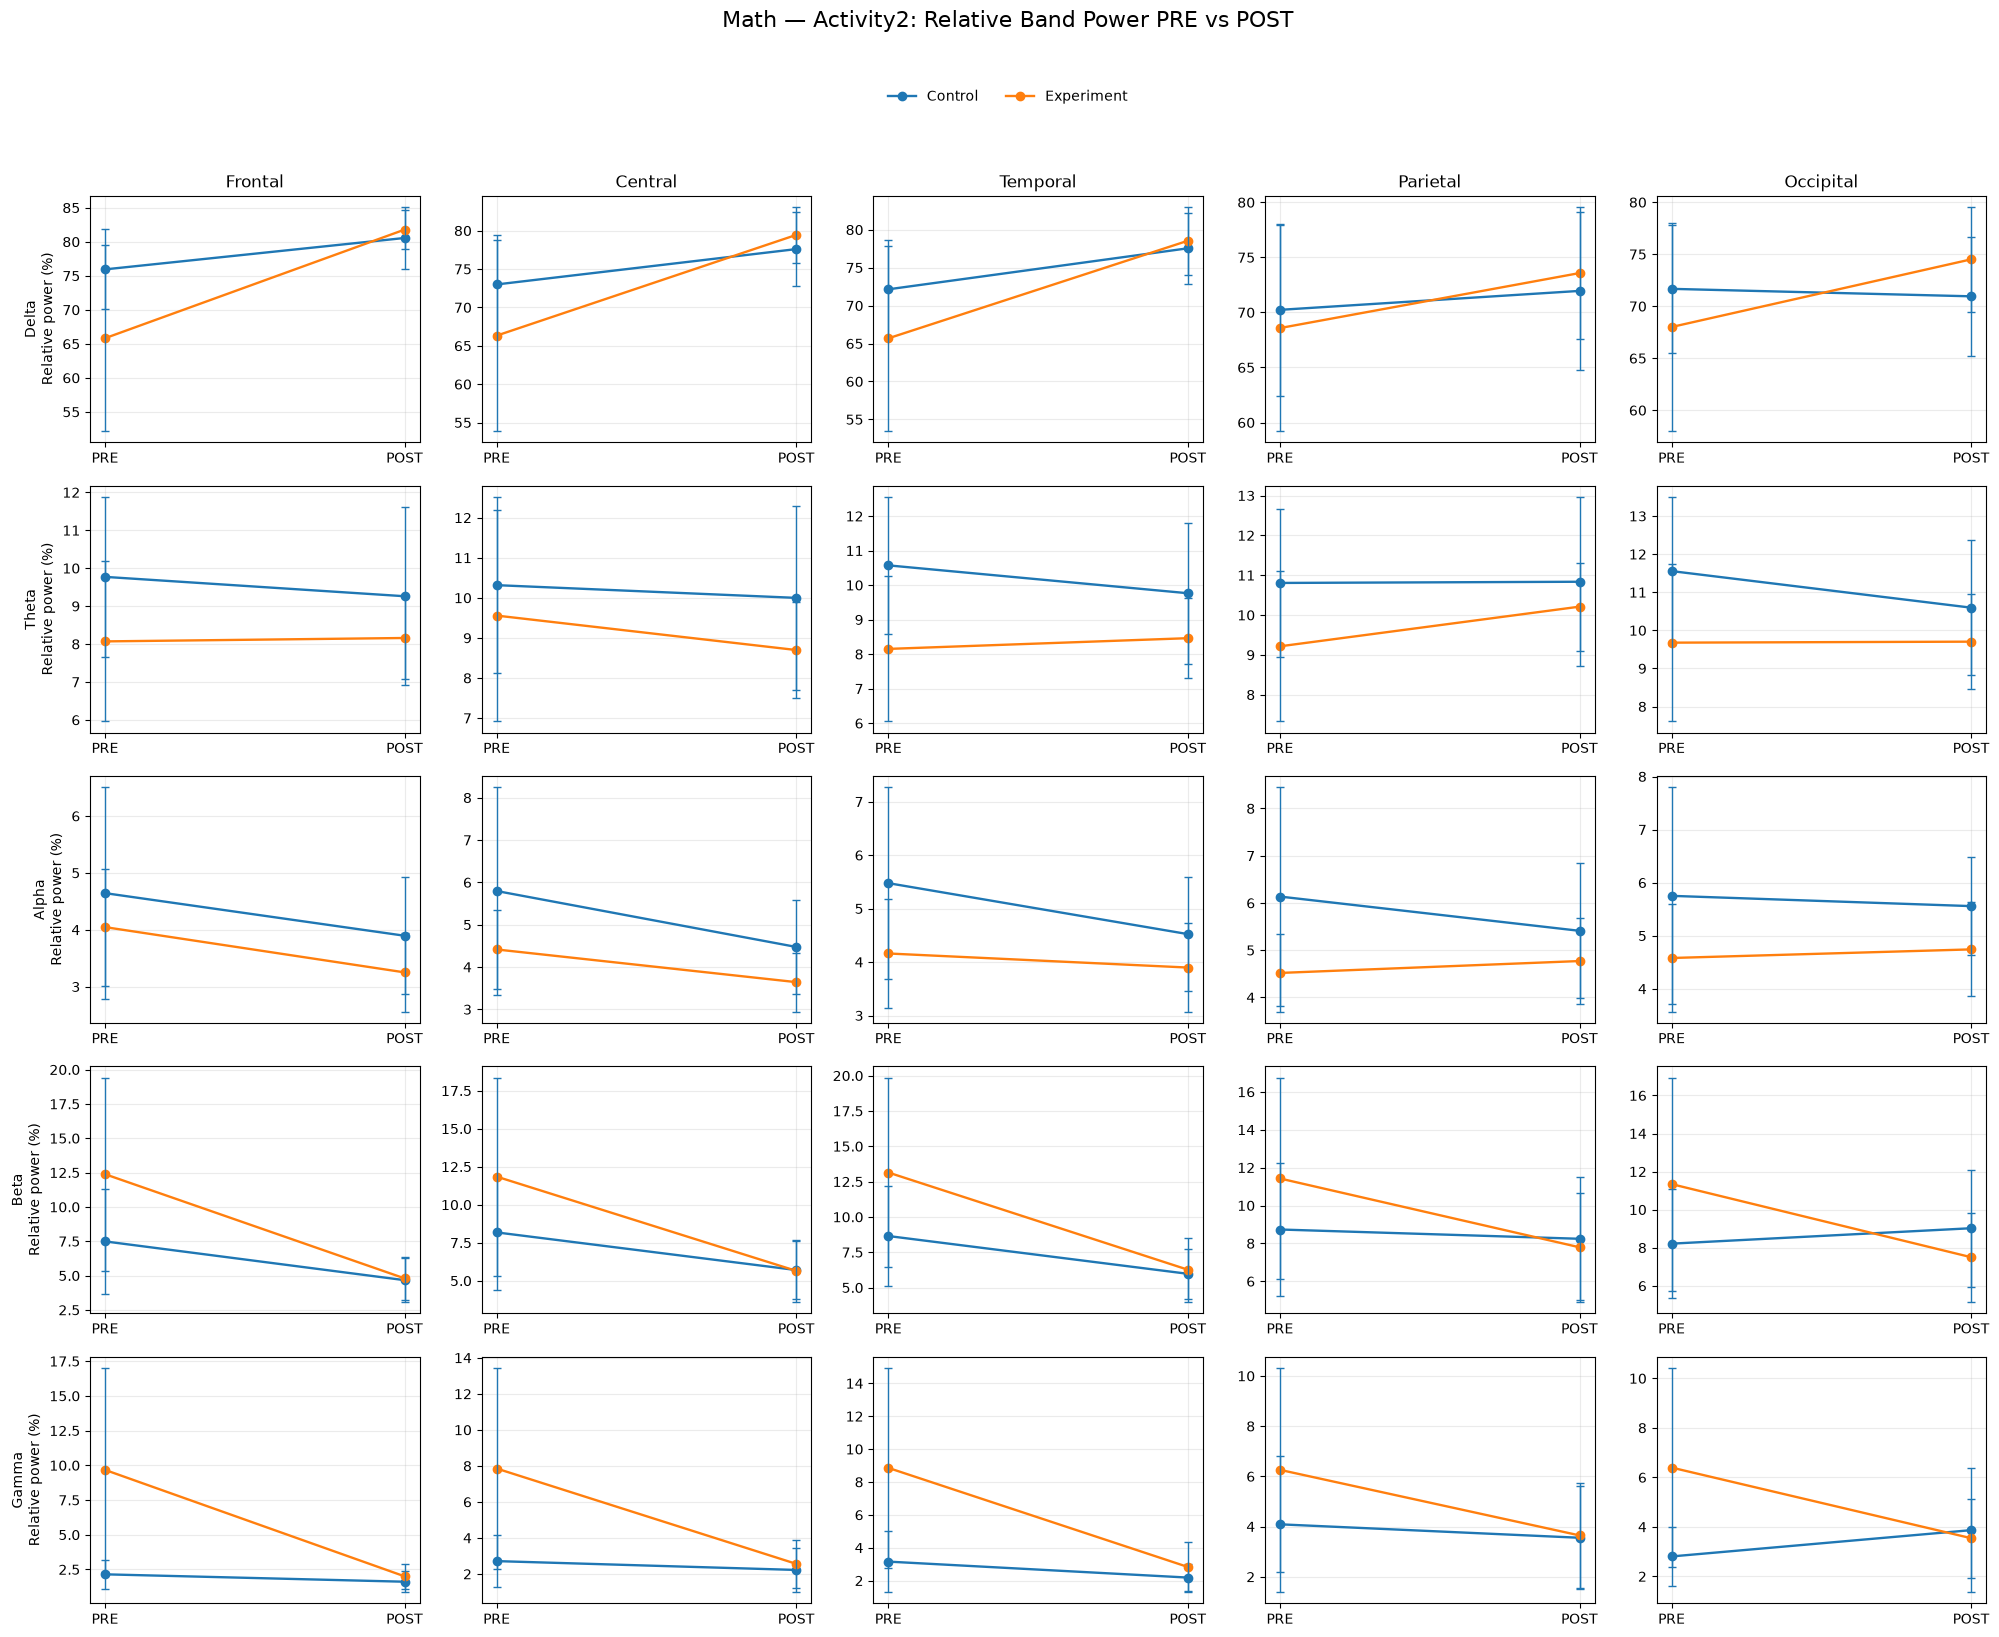

Saved: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure2_activity_relative_power/figure2_math_activity2_relative_power_pre_post.png


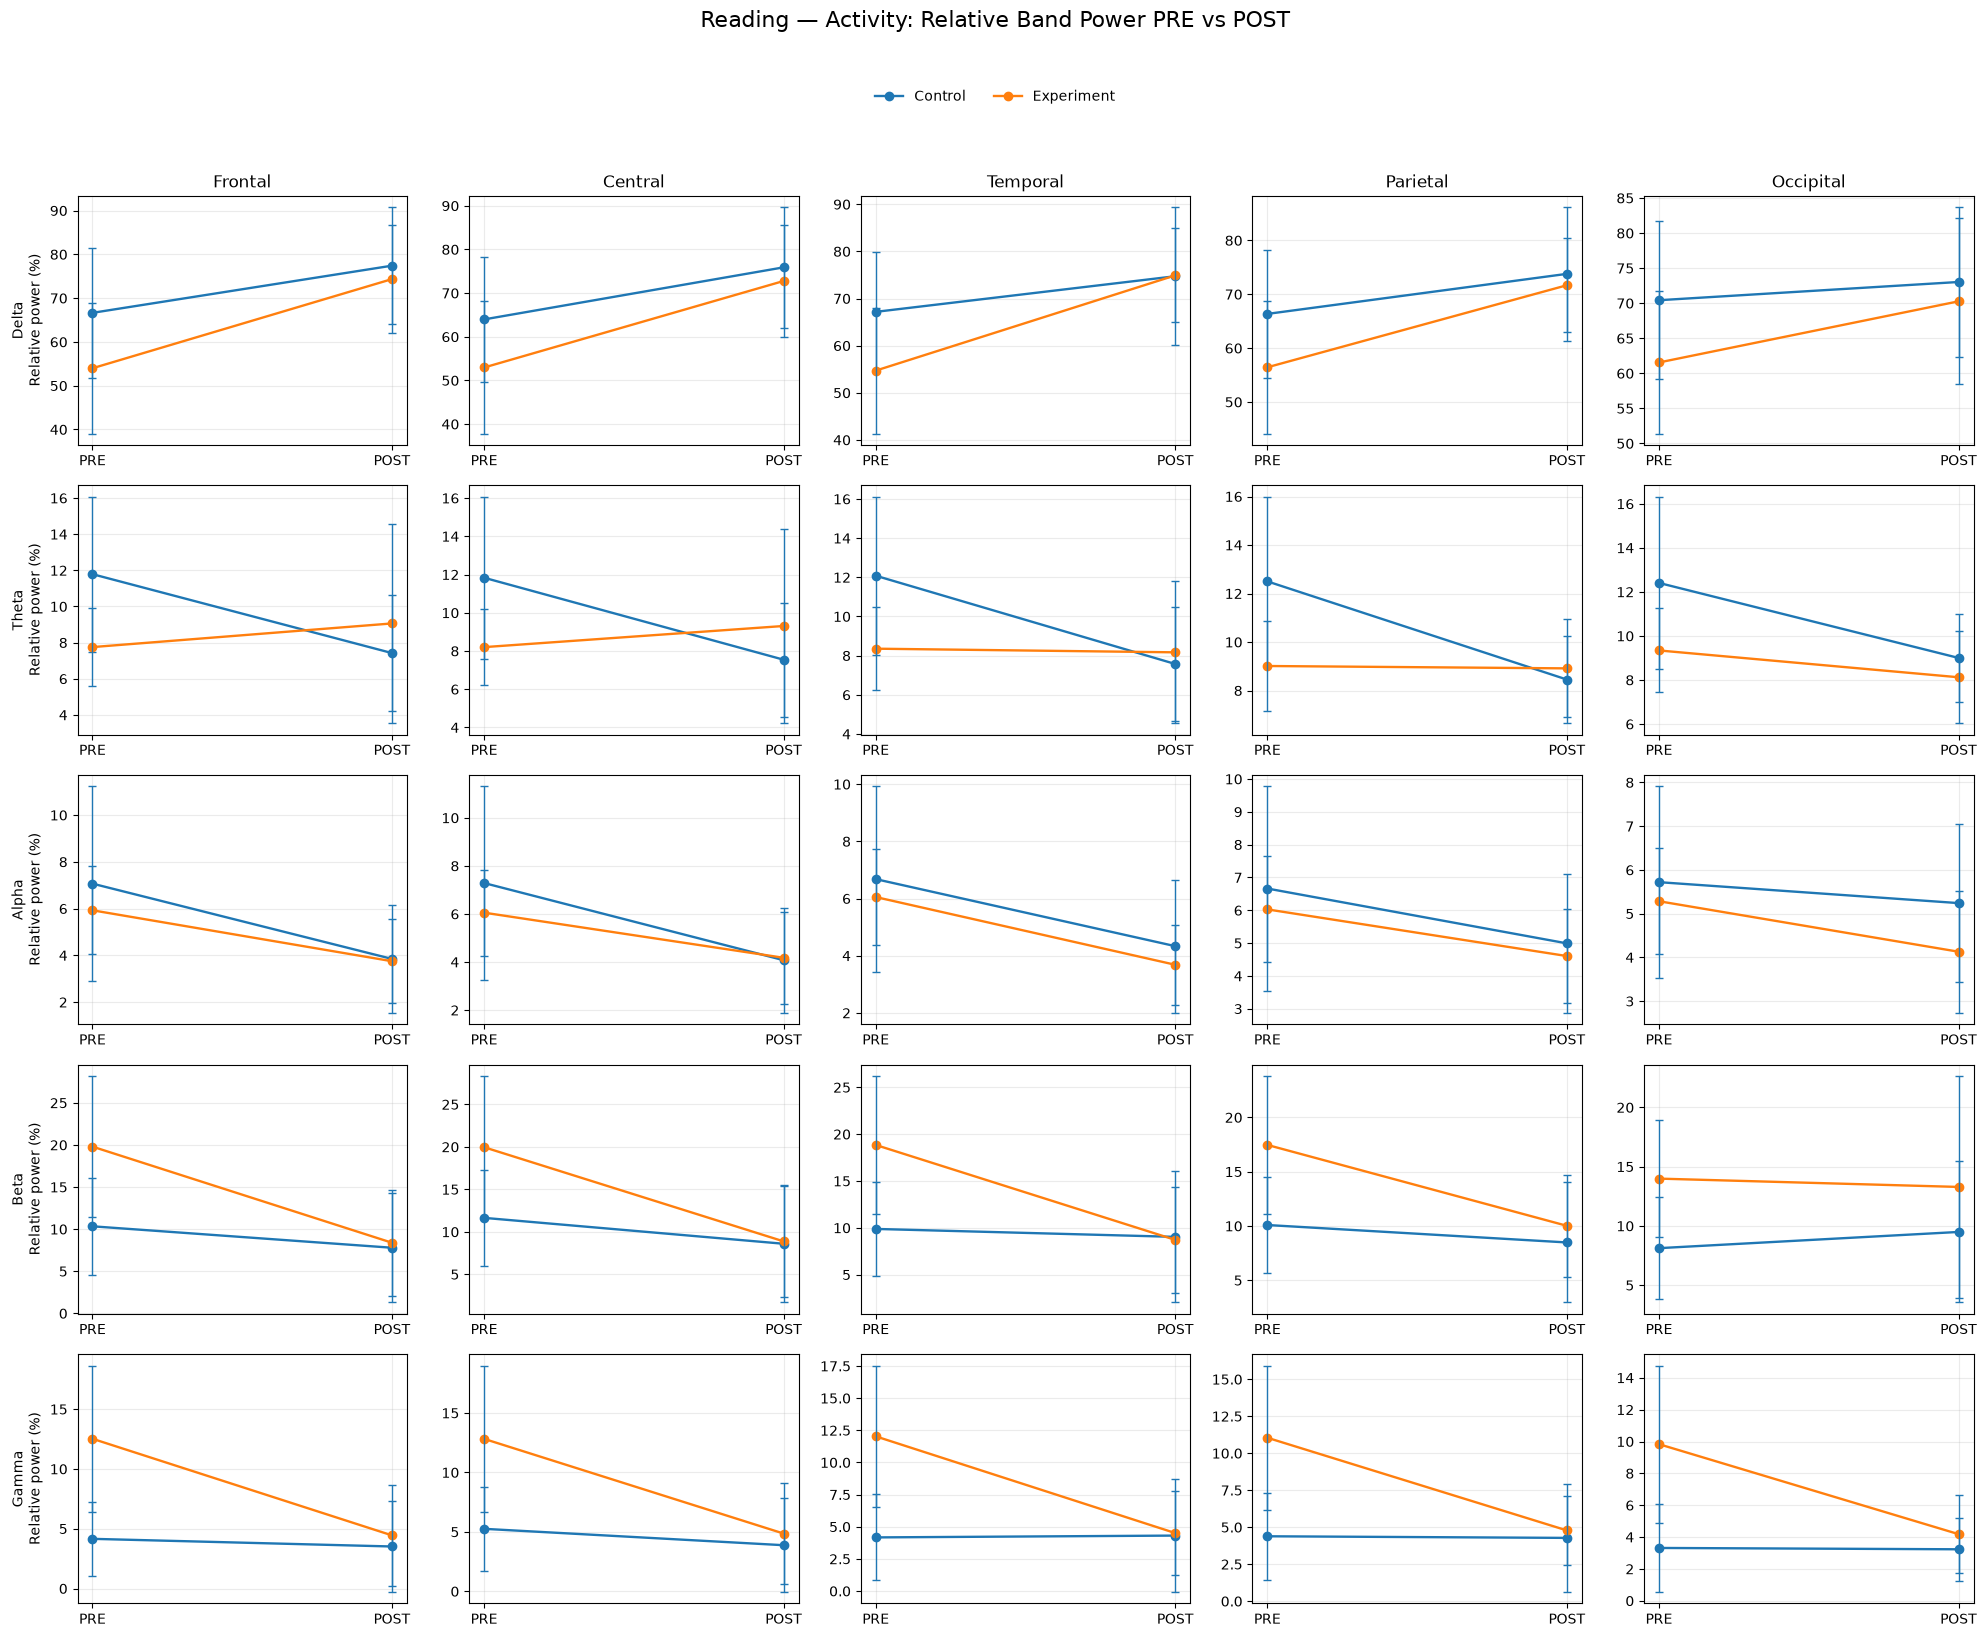

Saved: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/phase3_figures/figure2_activity_relative_power/figure2_reading_activity_relative_power_pre_post.png


In [4]:
def plot_condition(task_name, condition_name, filename):
    plot_data = summary[(summary['task']==task_name) & (summary['condition']==condition_name)]
    fig, axes = plt.subplots(5, 5, figsize=(20, 16), sharex=False, sharey=False)
    for i, band in enumerate(BANDS):
        for j, roi in enumerate(ROIS):
            ax = axes[i,j]
            sub = plot_data[(plot_data['band']==band) & (plot_data['roi']==roi)]
            for group in GROUPS:
                g = sub[sub['group']==group].set_index('session').reindex(SESSIONS)
                x = np.arange(len(SESSIONS))
                y = g['mean'].to_numpy(dtype=float)
                ci = g['ci95'].to_numpy(dtype=float)
                ax.plot(x, y, marker='o', linewidth=1.7, label=group)
                if np.isfinite(ci).any():
                    ax.errorbar(x, y, yerr=ci, fmt='none', capsize=3, linewidth=1)
            ax.set_xticks([0,1], SESSIONS)
            if i==0: ax.set_title(roi)
            if j==0: ax.set_ylabel(f'{band.capitalize()}\nRelative power (%)')
            ax.grid(True, alpha=.25)
    handles, labels = axes[0,0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .978), ncol=2, frameon=False)
    fig.suptitle(f'{task_name} — {condition_name}: Relative Band Power PRE vs POST', y=1.02, fontsize=16)
    fig.tight_layout(rect=[0,0,1,.95])
    out = output_dir / filename
    fig.savefig(out, dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved:', out)

plot_condition('Math','Activity1','figure2_math_activity1_relative_power_pre_post.png')
plot_condition('Math','Activity2','figure2_math_activity2_relative_power_pre_post.png')
plot_condition('Reading','Activity','figure2_reading_activity_relative_power_pre_post.png')

## Outputs and interpretation guardrails

Generated figures and summary CSV are saved in `phase3_figures/figure2_activity_relative_power`. Inspect patterns descriptively first. Do not interpret visual differences as statistically significant; Phase 2 tests remain the inferential source. Note group/session sample sizes in the summary CSV and the task-specific EEG coverage limitations.